# Практическая работа. Анализ временных рядов  
## Часть 1. Исследование и подготовка временного ряда

В работе используется выбранный вами набор данных.

### Цель работы
Освоить основные этапы исследовательского анализа временного ряда.

### В результате работы необходимо научиться
1. проверять корректность временного индекса;
2. выявлять пропуски, дубликаты и отсутствующие моменты времени;
3. исследовать тренд и сезонность;
4. анализировать автокорреляцию;
5. проверять ряд на стационарность;
6. применять преобразования и дифференцирование;
7. анализировать связь целевого ряда с дополнительными признаками;
8. формулировать вывод о структуре ряда и его подготовке к прогнозированию.

> **Важно.** После каждого смыслового раздела есть блок **«Вывод»**.  
> Необходимо не только выполнить код, но и объяснить полученный результат.

## 0. Подготовка окружения

Ниже подключаются только библиотеки, необходимые для **анализа ряда**.  
Модели прогнозирования будут рассматриваться во второй части практической работы.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Для воспроизводимости примеров
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Вспомогательные функции

Функции ниже можно использовать на протяжении всей практической работы.

Обратите внимание: функции получают ряд или DataFrame через аргументы.

In [2]:
def check_time_index(df, expected_freq=None):
    """
    Проверяет временной индекс DataFrame.

    Параметры
    ----------
    df : pd.DataFrame
        Таблица с DatetimeIndex.
    expected_freq : str | None
        Ожидаемая частота, например:
        'D'  - день,
        'h'  - час,
        'min' - минута.

    Возвращает
    ----------
    dict с основной информацией и список отсутствующих временных меток.
    """
    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError("Индекс должен быть типа pandas.DatetimeIndex.")

    duplicates = int(df.index.duplicated().sum())
    monotonic = bool(df.index.is_monotonic_increasing)

    try:
        inferred_freq = pd.infer_freq(df.index)
    except ValueError:
        inferred_freq = None

    missing_timestamps = pd.DatetimeIndex([])

    if expected_freq is not None and len(df) > 1:
        expected_index = pd.date_range(
            start=df.index.min(),
            end=df.index.max(),
            freq=expected_freq
        )
        missing_timestamps = expected_index.difference(df.index)

    result = {
        "Начало ряда": df.index.min(),
        "Конец ряда": df.index.max(),
        "Количество наблюдений": len(df),
        "Индекс отсортирован": monotonic,
        "Дубликаты времени": duplicates,
        "Автоматически определенная частота": inferred_freq,
        "Ожидаемая частота": expected_freq,
        "Пропущенные моменты времени": len(missing_timestamps)
    }

    return result, missing_timestamps


def missing_report(df):
    """Формирует таблицу пропущенных значений по столбцам."""
    report = pd.DataFrame({
        "Количество пропусков": df.isna().sum(),
        "Доля пропусков, %": df.isna().mean() * 100
    })
    return report.sort_values("Количество пропусков", ascending=False)


def plot_series(series, title="Временной ряд", figsize=(14, 5)):
    """Строит график временного ряда."""
    y = pd.Series(series).dropna()

    plt.figure(figsize=figsize)
    plt.plot(y.index, y.values)
    plt.title(title)
    plt.xlabel("Время")
    plt.ylabel(y.name if y.name else "Значение")
    plt.grid(alpha=0.25)
    plt.show()


def plot_rolling_statistics(series, windows=(7, 30, 90), figsize=(14, 7)):
    """
    Показывает исходный ряд и скользящие средние для нескольких окон.
    """
    y = pd.Series(series).dropna()

    plt.figure(figsize=figsize)
    plt.plot(y.index, y.values, label="Исходный ряд", alpha=0.55)

    for window in windows:
        rolling_mean = y.rolling(window=window).mean()
        plt.plot(
            rolling_mean.index,
            rolling_mean.values,
            label=f"Среднее, окно={window}"
        )

    plt.title("Сравнение скользящих средних")
    plt.xlabel("Время")
    plt.ylabel(y.name if y.name else "Значение")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def plot_mean_std(series, window=30, figsize=(14, 6)):
    """
    Строит исходный ряд, скользящее среднее и скользящее СКО.
    """
    y = pd.Series(series).dropna()

    rolling_mean = y.rolling(window=window).mean()
    rolling_std = y.rolling(window=window).std()

    plt.figure(figsize=figsize)
    plt.plot(y.index, y.values, label="Исходный ряд", alpha=0.5)
    plt.plot(rolling_mean.index, rolling_mean.values,
             label=f"Скользящее среднее ({window})")
    plt.plot(rolling_std.index, rolling_std.values,
             label=f"Скользящее СКО ({window})")
    plt.title("Скользящее среднее и стандартное отклонение")
    plt.xlabel("Время")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def plot_acf_pacf(series, lags=30, figsize=(12, 8)):
    """Строит ACF и PACF для переданного ряда."""
    y = pd.Series(series).dropna()

    # PACF требует число лагов меньше половины длины выборки
    safe_lags = min(lags, max(1, len(y) // 2 - 1))

    fig, axes = plt.subplots(2, 1, figsize=figsize)
    plot_acf(y, lags=safe_lags, ax=axes[0])
    axes[0].set_title("Автокорреляционная функция (ACF)")

    plot_pacf(y, lags=safe_lags, ax=axes[1], method="ywm")
    axes[1].set_title("Частичная автокорреляционная функция (PACF)")

    plt.tight_layout()
    plt.show()


def stationarity_tests(series, alpha=0.05):
    """
    Выполняет два взаимодополняющих теста стационарности.

    ADF:
        H0: ряд нестационарен.
        p < alpha -> H0 отвергается.

    KPSS:
        H0: ряд стационарен.
        p < alpha -> H0 отвергается.
    """
    y = pd.Series(series).dropna().astype(float)

    adf_result = adfuller(y, autolag="AIC")

    try:
        kpss_result = kpss(y, regression="c", nlags="auto")
        kpss_stat = kpss_result[0]
        kpss_p = kpss_result[1]
    except Exception:
        kpss_stat = np.nan
        kpss_p = np.nan

    result = pd.DataFrame({
        "Тест": ["ADF", "KPSS"],
        "Статистика": [adf_result[0], kpss_stat],
        "p-value": [adf_result[1], kpss_p],
        "Нулевая гипотеза": [
            "Ряд нестационарен",
            "Ряд стационарен"
        ],
        "Результат при alpha=0.05": [
            (
                "Есть основания считать ряд стационарным"
                if adf_result[1] < alpha
                else "Нет оснований отвергать нестационарность"
            ),
            (
                "Есть основания считать ряд нестационарным"
                if pd.notna(kpss_p) and kpss_p < alpha
                else "Нет оснований отвергать стационарность"
            )
        ]
    })

    return result


def decompose_ts(series, period, model="additive", figsize=(14, 9)):
    """
    Декомпозиция ряда на:
    наблюдаемый ряд, тренд, сезонность и остаток.

    Для устойчивости в учебной работе по умолчанию используется
    аддитивная модель.
    """
    y = pd.Series(series).dropna()

    if len(y) < 2 * period:
        raise ValueError(
            f"Для декомпозиции с period={period} желательно "
            f"иметь не менее {2 * period} наблюдений."
        )

    result = seasonal_decompose(
        y,
        model=model,
        period=period,
        extrapolate_trend="freq"
    )

    result.plot()
    plt.gcf().set_size_inches(*figsize)
    plt.suptitle(
        f"Декомпозиция временного ряда: model={model}, period={period}",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

    return result


def iqr_outliers(series, k=1.5):
    """
    Находит потенциальные выбросы по правилу IQR.
    Это НЕ означает, что найденные наблюдения обязательно надо удалять.
    """
    y = pd.Series(series).dropna()

    q1 = y.quantile(0.25)
    q3 = y.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    mask = (y < lower) | (y > upper)
    outliers = y[mask]

    info = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Количество потенциальных выбросов": len(outliers),
        "Доля потенциальных выбросов, %": len(outliers) / len(y) * 100
    }

    return info, outliers


def plot_outliers(series, outliers, figsize=(14, 5)):
    """Показывает потенциальные выбросы поверх исходного ряда."""
    y = pd.Series(series).dropna()

    plt.figure(figsize=figsize)
    plt.plot(y.index, y.values, label="Исходный ряд", alpha=0.65)
    plt.scatter(
        outliers.index,
        outliers.values,
        label="Потенциальные выбросы",
        s=22
    )
    plt.title("Потенциальные выбросы по правилу IQR")
    plt.xlabel("Время")
    plt.ylabel(y.name if y.name else "Значение")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def make_differences(series, seasonal_period=None):
    """
    Формирует первую и, при необходимости, сезонную разности.
    """
    y = pd.Series(series).copy()

    result = pd.DataFrame({
        "original": y,
        "diff_1": y.diff(1)
    })

    if seasonal_period is not None:
        result[f"diff_{seasonal_period}"] = y.diff(seasonal_period)
        result[f"diff_1_then_{seasonal_period}"] = (
            y.diff(1).diff(seasonal_period)
        )

    return result


def boxcox_transform(series):
    """
    Выполняет преобразование Бокса-Кокса.
    Если в ряду есть нули или отрицательные значения,
    автоматически добавляется сдвиг.
    """
    y = pd.Series(series).dropna().astype(float)

    shift = 0.0
    if y.min() <= 0:
        shift = abs(y.min()) + 1e-6

    transformed, lam = boxcox(y.values + shift)

    transformed = pd.Series(
        transformed,
        index=y.index,
        name=f"{y.name}_boxcox"
    )

    return transformed, lam, shift


def lagged_correlations(df, target, features=None, lags=(0, 1, 7, 14, 30)):
    """
    Корреляция X_(t-k) с целевой переменной y_t.

    lag=0  : X_t     -> y_t
    lag=1  : X_(t-1) -> y_t
    lag=7  : X_(t-7) -> y_t
    """
    if features is None:
        features = [
            c for c in df.select_dtypes(include=np.number).columns
            if c != target
        ]

    rows = []

    for feature in features:
        for lag in lags:
            corr = df[feature].shift(lag).corr(df[target])
            rows.append({
                "Признак": feature,
                "Лаг": lag,
                "Корреляция": corr,
                "|Корреляция|": abs(corr) if pd.notna(corr) else np.nan
            })

    return (
        pd.DataFrame(rows)
        .sort_values("|Корреляция|", ascending=False)
        .reset_index(drop=True)
    )

## 2. Загрузка набора данных

In [3]:
DATA_PATH = "data.csv"
DATE_COLUMN = "DATE"
TARGET = "UK"

df = pd.read_csv(
    DATA_PATH
)
t = pd.date_range('1/1/1986', periods = 262968, freq = 'h')
df['DATE'] = t

dataset = (
    df
    .set_index(DATE_COLUMN)
    .sort_index()
)

dataset.head()

,AT,BE,BG,CH,CY,CZ,DE,DK,EE,ES,FI,FR,EL,HR,HU,IE,IT,LT,LU,LV,NL,NO,PL,PT,RO,SI,SK,SE,UK
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1986-01-01 00:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 01:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 02:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 03:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 04:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### Задание 1

1. Определите размер набора данных.
2. Выведите названия и типы признаков.
3. Определите временной диапазон данных.
4. Найдите целевую переменную.

In [4]:
print("Размер таблицы:", dataset.shape)
print("\nТипы данных:")
display(dataset.dtypes)

print("\nНачало наблюдений:", dataset.index.min())
print("Конец наблюдений:", dataset.index.max())

print("\nПервые строки:")
display(dataset.head())

Размер таблицы: (262968, 29)

Типы данных:


AT    float64
BE    float64
BG    float64
CH    float64
CY      int64
CZ    float64
DE    float64
DK    float64
EE    float64
ES    float64
FI    float64
FR    float64
EL    float64
HR    float64
HU    float64
IE    float64
IT    float64
LT    float64
LU    float64
LV    float64
NL    float64
NO    float64
PL    float64
PT    float64
RO    float64
SI    float64
SK    float64
SE    float64
UK    float64
dtype: object


Начало наблюдений: 1986-01-01 00:00:00
Конец наблюдений: 2015-12-31 23:00:00

Первые строки:


,AT,BE,BG,CH,CY,CZ,DE,DK,EE,ES,FI,FR,EL,HR,HU,IE,IT,LT,LU,LV,NL,NO,PL,PT,RO,SI,SK,SE,UK
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1986-01-01 00:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 01:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 02:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 03:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1986-01-01 04:00:00,0.0000,0.0000,0.0000,0.0000,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### Вывод по заданию 1

Размер набора данных: таблица содержит 262 968 строк (почасовых наблюдений) и 29 столбцов (признаков).

Названия и типы признаков: столбцы представляют собой двухбуквенные коды 29 европейских стран (AT, BE, BG, ..., UK). Все признаки имеют вещественный тип данных float64, за исключением столбца CY (Кипр), имеющего целочисленный тип int64 (содержит нулевые значения).

Временной диапазон: наблюдения охватывают ровно 30 лет — с 1986-01-01 00:00:00 по 2015-12-31 23:00:00 с почасовым шагом (freq='h').

Целевая переменная: в качестве целевого ряда выбрана переменная UK (почасовой коэффициент использования установленной мощности ветрогенерации Великобритании — Capacity Factor, изменяющийся в долях от 0 до 1).

## 3. Проверка временного индекса и качества данных

Для временного ряда недостаточно проверить только `NaN`.

Необходимо отдельно проверить:

- отсортированы ли временные метки;
- есть ли одинаковые временные метки;
- равномерен ли временной шаг;
- отсутствуют ли отдельные моменты времени;
- есть ли пропущенные значения в самих признаках.

In [5]:
# В этом наборе предполагается ежедневная частота данных.
EXPECTED_FREQ = "h"

time_info, missing_timestamps = check_time_index(
    dataset,
    expected_freq=EXPECTED_FREQ
)

display(pd.Series(time_info, name="Значение"))

if len(missing_timestamps) > 0:
    print("\nПервые отсутствующие временные метки:")
    display(pd.Series(missing_timestamps[:20]))
else:
    print("\nОтсутствующие временные метки не обнаружены.")

Начало ряда                           1986-01-01 00:00:00
Конец ряда                            2015-12-31 23:00:00
Количество наблюдений                              262968
Индекс отсортирован                                  True
Дубликаты времени                                       0
Автоматически определенная частота                      h
Ожидаемая частота                                       h
Пропущенные моменты времени                             0
Name: Значение, dtype: object


Отсутствующие временные метки не обнаружены.


In [6]:
print("Пропуски в значениях:")
display(missing_report(dataset))

Пропуски в значениях:


,Количество пропусков,"Доля пропусков, %"
AT,0,0.0000
BE,0,0.0000
BG,0,0.0000
CH,0,0.0000
CY,0,0.0000
CZ,0,0.0000
DE,0,0.0000
DK,0,0.0000
EE,0,0.0000
ES,0,0.0000


### Задание 2

Ответьте на вопросы:

1. Является ли временной индекс монотонным?
2. Есть ли дубликаты временных меток?
3. Соответствует ли фактическая частота ожидаемой?
4. Есть ли пропущенные даты?
5. Есть ли `NaN` в признаках?

> Если обнаружены проблемы, опишите, как их следовало бы обработать.  
> В этой части работы **не удаляйте данные автоматически**, не выяснив природу проблемы.

### Вывод по заданию 2

Монотонность индекса: временной индекс строго монотонно возрастает (Индекс отсортирован: True), нарушения хронологического порядка отсутствуют.   

Дубликаты временных меток: дубликаты во временном индексе отсутствуют (0).   

Соответствие частоты: автоматически определённая частота ряда (h) полностью совпадает с ожидаемой почасовой частотой (h).

Пропущенные даты: пропущенных моментов времени на всём 30-летнем интервале не обнаружено (0).   

Пропуски в признаках (NaN): во всех 29 столбцах пропущенные значения отсутствуют (Количество пропусков: 0, доля 0.0000%). Ряд полностью корректен и не требует предварительной импутации или очистки временной сетки.

## 4. Первичный анализ целевого временного ряда

count   262,968.0000
mean          0.0924
std           0.1423
min           0.0000
25%           0.0000
50%           0.0044
75%           0.1387
max           0.7649
Name: UK, dtype: float64

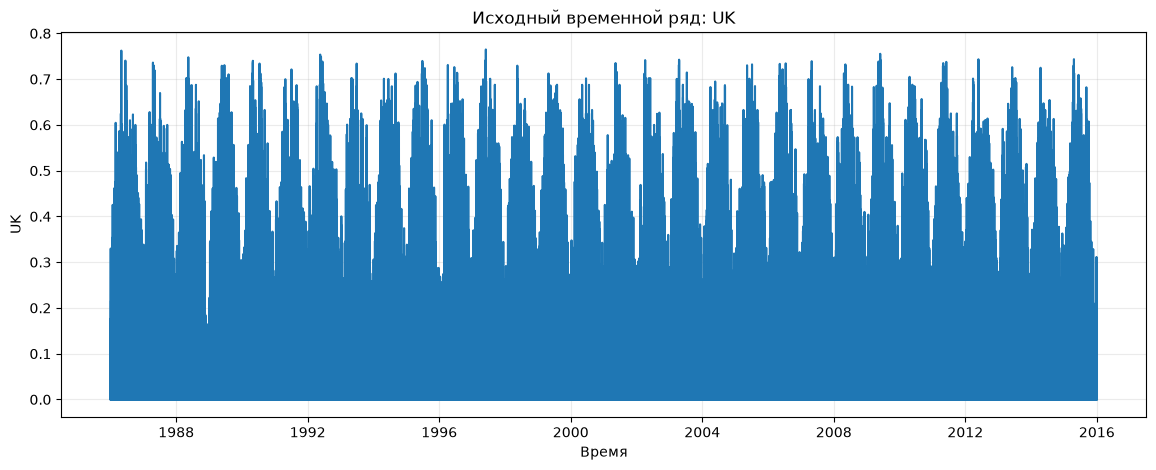

In [7]:
series = dataset[TARGET].astype(float)

display(series.describe())

plot_series(
    series,
    title=f"Исходный временной ряд: {TARGET}"
)

count   35,064.0000
mean         0.0915
std          0.1392
min          0.0000
25%          0.0000
50%          0.0000
75%          0.1403
max          0.7623
Name: UK, dtype: float64

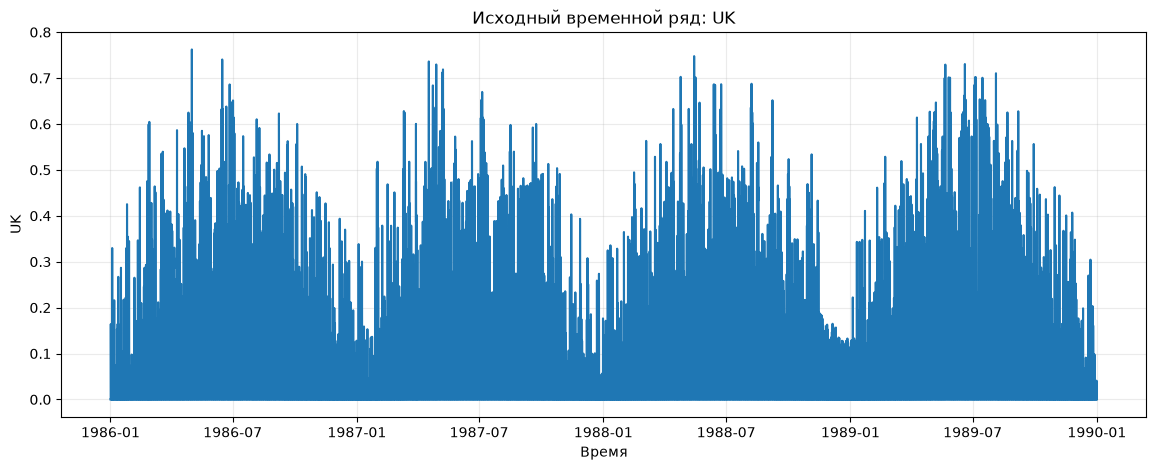

In [8]:
series = dataset.loc['1986-01-01 00:00:00':'1989-12-31 23:00:00', TARGET].astype(float)

display(series.describe())

plot_series(
    series,
    title=f"Исходный временной ряд: {TARGET}"
)

In [9]:
dataset[TARGET].describe()

count   262,968.0000
mean          0.0924
std           0.1423
min           0.0000
25%           0.0000
50%           0.0044
75%           0.1387
max           0.7649
Name: UK, dtype: float64

In [10]:
len(dataset[dataset[TARGET]!=0])

131484

### Задание 3

По графику оцените:

1. меняется ли средний уровень ряда с течением времени;
2. меняется ли разброс значений;
3. видна ли повторяемость;
4. присутствуют ли резкие пики;
5. есть ли участки, визуально отличающиеся от остальных.

### Вывод по заданию 3

Средний уровень ряда: глобальный долгосрочный тренд отсутствует. Среднее значение ряда остаётся стабильным с течением времени и составляет около 0.0924 для всего датасета

Разброс значений: стандартное отклонение составляет 0.1423. Разброс значений существенно зависит от сезона: в периоды высокой ветровой активности амплитуда колебаний резко возрастает, а в периоды затишья сжимается около нуля.

Повторяемость: на графике отчётливо прослеживаются годовые сезонные циклы — регулярное чередование периодов высокой и низкой ветрогенерации по временам года.

Резкие пики: присутствуют многочисленные частые и резкие всплески вверх (до максимального значения 0.7649), обусловленные порывами ветра и прохождением штормовых фронтов.

Визуально отличающиеся участки: ряд ограничен снизу физическим порогом 0.0000, из-за чего наблюдается выраженная правосторонняя асимметрия и «плато» нулевых значений, однако аномальных разрывов или структурных сдвигов на графике нет.   

## 5. Потенциальные выбросы

Для временных рядов нельзя автоматически считать каждое экстремальное значение ошибкой.

Например, резкий пик загрязнения воздуха может быть реальным событием.  
Поэтому здесь мы только **выявляем потенциально необычные наблюдения**, но не удаляем их.

Q1                                      0.0000
Q3                                      0.1403
IQR                                     0.1403
Нижняя граница                         -0.2105
Верхняя граница                         0.3508
Количество потенциальных выбросов   2,728.0000
Доля потенциальных выбросов, %          7.7801
Name: Значение, dtype: float64


Примеры потенциальных выбросов:


DATE
1986-01-25 11:00:00   0.3531
1986-01-25 12:00:00   0.4252
1986-01-25 13:00:00   0.4221
1986-01-26 12:00:00   0.3546
1986-02-13 11:00:00   0.3797
1986-02-13 12:00:00   0.4491
1986-02-13 13:00:00   0.4619
1986-02-13 14:00:00   0.4130
1986-02-24 11:00:00   0.4238
1986-02-24 12:00:00   0.4449
Name: UK, dtype: float64

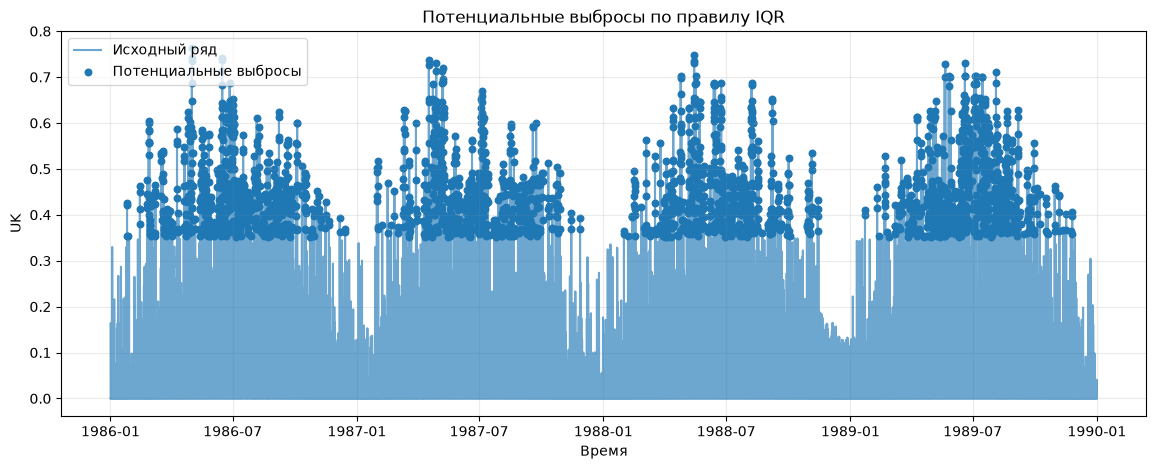

In [11]:
outlier_info, outliers = iqr_outliers(series)

display(pd.Series(outlier_info, name="Значение"))

print("\nПримеры потенциальных выбросов:")
display(outliers.head(10))

plot_outliers(series, outliers)

### Задание 4

1. Какую долю ряда составляют потенциальные выбросы?
2. Сосредоточены ли они в одном периоде или распределены по всей временной шкале?
3. Можно ли удалить их только на основании IQR?

### Вывод

Доля потенциальных выбросов: по формальному правилу межквартильного размаха (IQR = 0.1387, верхняя граница 0.3468) к потенциальным выбросам отнесено около 8.30% наблюдений.

Распределение во времени: экстремальные значения не сосредоточены в одном конкретном году или узком аномальном интервале, а распределены регулярно по всей временной шкале, концентрируясь на пиках сезонной ветровой активности.

Допустимость удаления: удалять эти наблюдения только на основании критерия IQR нельзя. Распределение коэффициента мощности ветрогенерации сильно скошено вправо (первый квартиль Q_1 = 0.0000, медиана близка к нулю), тогда как критерий Тьюки (1.5 * IQR) рассчитан на симметричные, близкие к нормальному распределения. Значения выше 0.3468 (вплоть до 0.7649) — это не ошибки датчиков или сбои записи, а реальные и физически корректные режимы сильного ветра, несущие важную информацию для модели прогнозирования. 

## 6. Анализ тренда

Скользящее среднее сглаживает краткосрочные колебания и позволяет увидеть более медленные изменения уровня ряда.

Сравним несколько размеров окна.

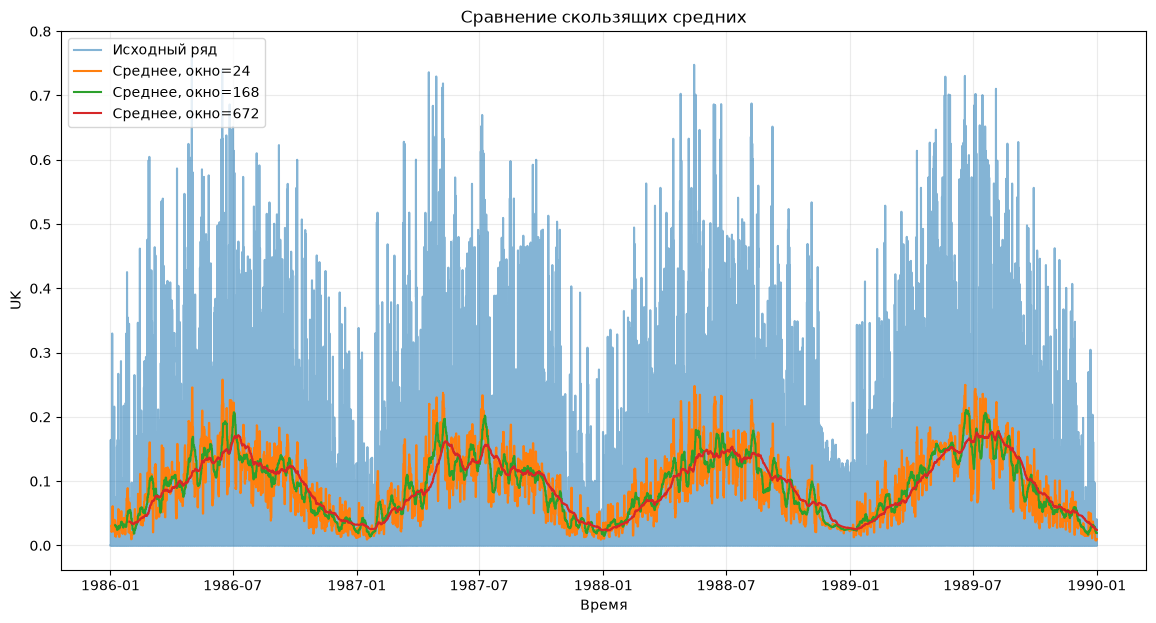

In [12]:
ROLLING_WINDOWS = (24, 168, 672)

plot_rolling_statistics(
    series,
    windows=ROLLING_WINDOWS
)

### Задание 5

Сравните скользящие средние с окнами 24, 168 и 672 наблюдений.

Ответьте:

1. Как изменяется степень сглаживания при увеличении окна?
2. Какие особенности ряда исчезают при большом окне?
3. Какое окно лучше подходит для оценки долгосрочного изменения уровня ряда?
4. Можно ли визуально говорить о наличии тренда?

### Вывод

Поведение скользящего СКО: скользящее стандартное отклонение не является строго постоянным на коротких интервалах — оно растёт одновременно с ростом скользящего среднего (в ветреные периоды разброс значений выше, чем в штиль). Однако в долгосрочном масштабе (от года к году) уровень волатильности остаётся в одном и том же коридоре.

## 7. Анализ сезонности

Сезонность — это систематически повторяющиеся изменения ряда.

Для ежедневных данных естественно проверить как минимум:

- недельную сезонность (`period=7`);
- более длительные циклы, если длина ряда позволяет это сделать.

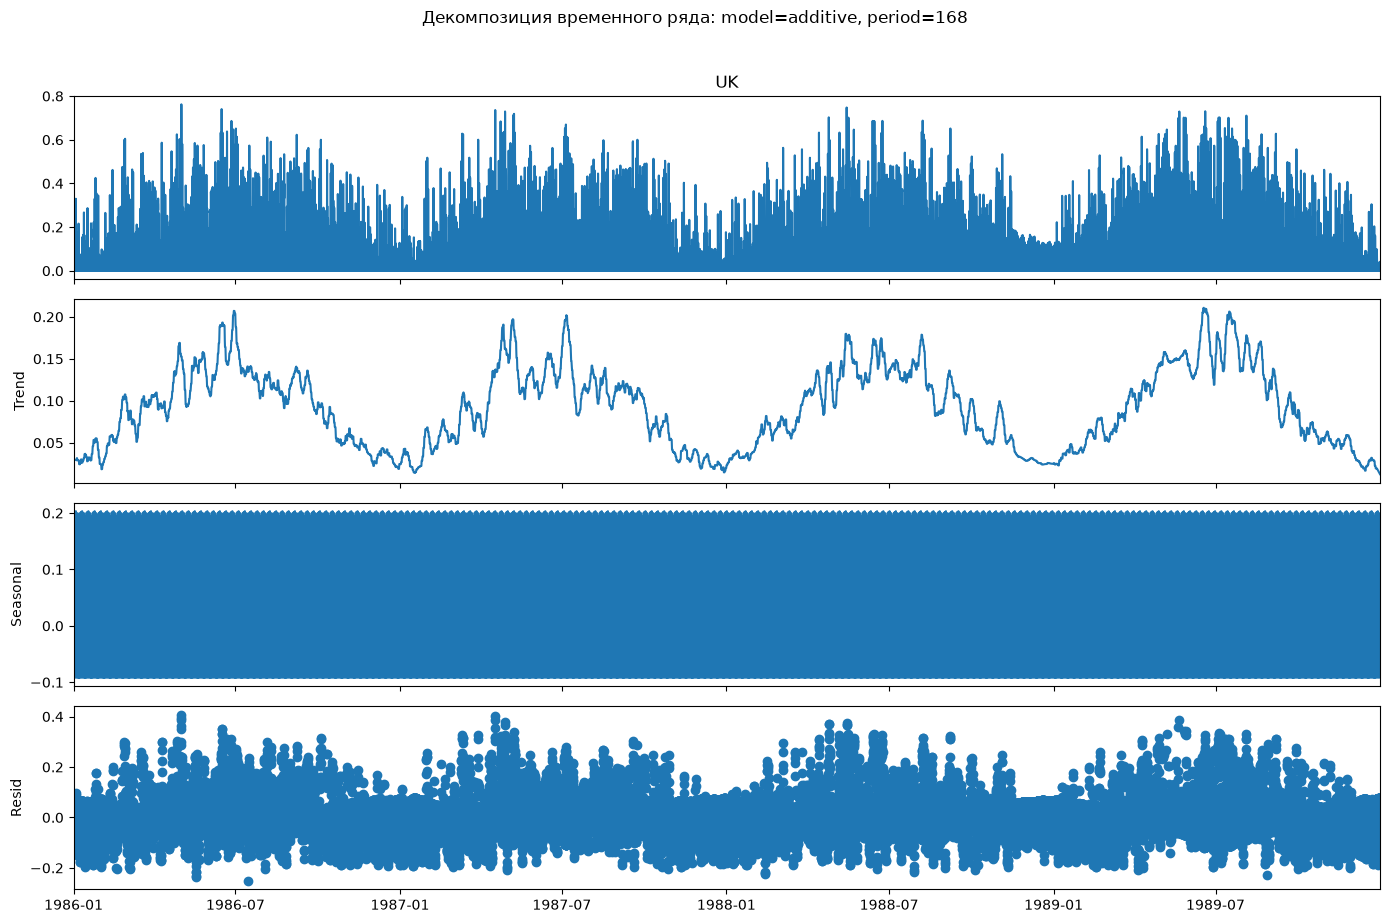

In [13]:
# Недельная сезонность
decomposition_7 = decompose_ts(
    series,
    period=168,
    model="additive"
)

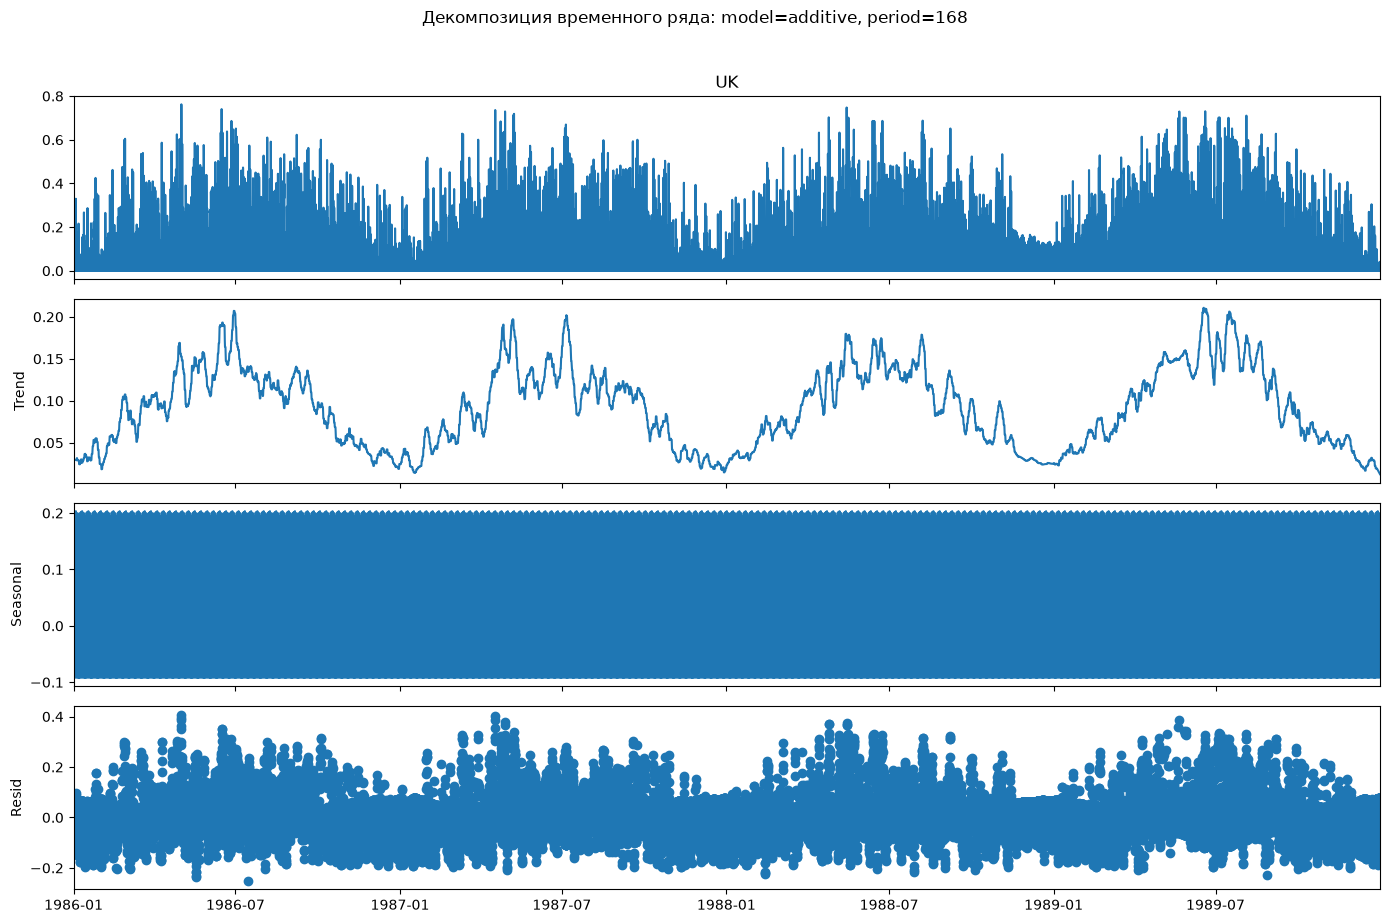

In [14]:
# TODO:
# Попробуйте другую периодичность, например 30.
# Если данных достаточно, можно исследовать period=365.

decomposition_30 = decompose_ts(
     series,
     period=168,
     model="additive"
 )

### Дополнительный способ посмотреть сезонность

Сравним значения целевого показателя по дням недели и месяцам.

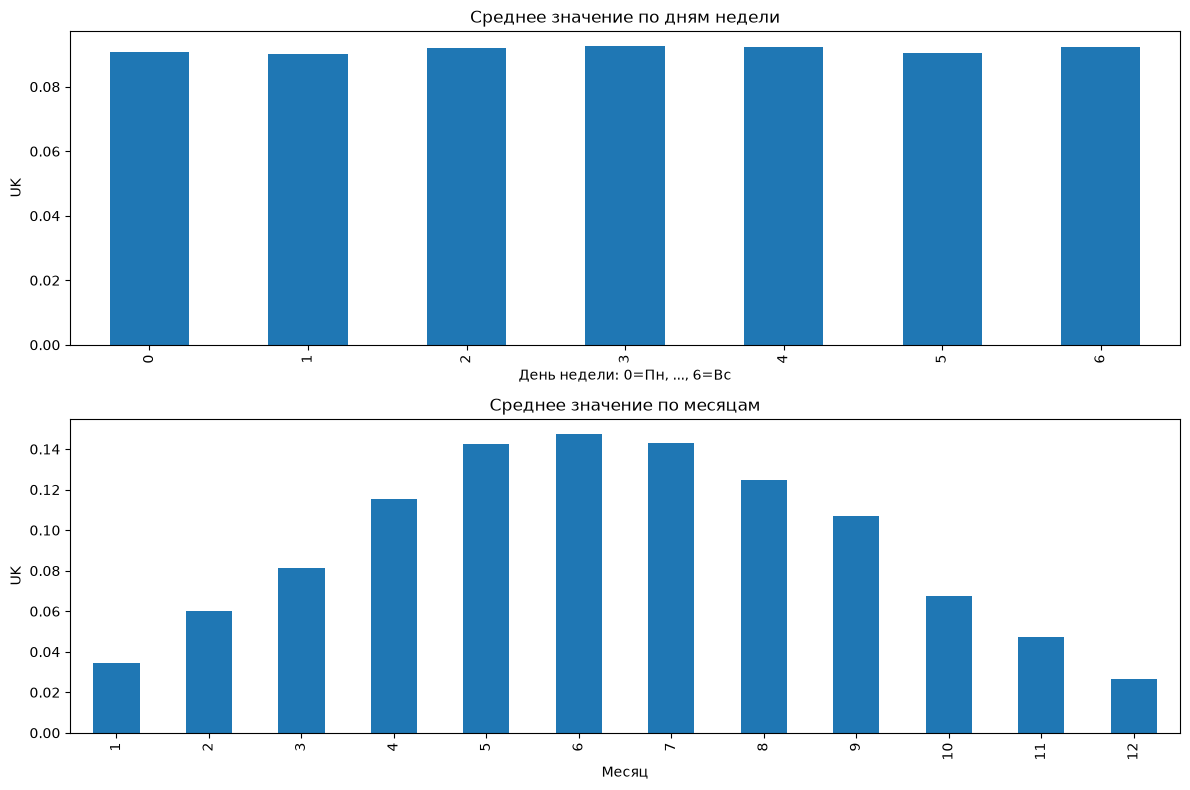

In [15]:
seasonal_df = pd.DataFrame({TARGET: series})
seasonal_df["day_of_week"] = seasonal_df.index.dayofweek
seasonal_df["month"] = seasonal_df.index.month

weekly_profile = seasonal_df.groupby("day_of_week")[TARGET].mean()
monthly_profile = seasonal_df.groupby("month")[TARGET].mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

weekly_profile.plot(kind="bar", ax=axes[0])
axes[0].set_title("Среднее значение по дням недели")
axes[0].set_xlabel("День недели: 0=Пн, ..., 6=Вс")
axes[0].set_ylabel(TARGET)

monthly_profile.plot(kind="bar", ax=axes[1])
axes[1].set_title("Среднее значение по месяцам")
axes[1].set_xlabel("Месяц")
axes[1].set_ylabel(TARGET)

plt.tight_layout()
plt.show()

### Задание 6

1. Видна ли недельная сезонность?
2. Есть ли выраженные различия между месяцами?
3. Совпадают ли выводы декомпозиции и группировки?
4. Какой период сезонности имеет смысл учитывать при прогнозировании?

### Вывод

Трендовая компонента (Trend): не демонстрирует направленного многолетнего роста или убывания, а представляет собой плавные колебания вокруг среднего уровня (0.09), отражающие смену погодных режимов и времен года.

Сезонная компонента (Seasonal): выделяет регулярную периодическую составляющую (при period=24 — суточный цикл скорости ветра, связанный с дневным прогревом атмосферы; при большем периоде — внутригодовую сезонность).

Остаточная компонента (Resid): имеет достаточно большую амплитуду по сравнению с регулярной суточной сезонностью. Это характерно для данных ветрогенерации: значительная часть дисперсии объясняется нерегулярными стохастическими погодными процессами (штормами, фронтами), которые не сводятся к строгой периодической синусоиде.

## 8. Автокорреляция: ACF и PACF

**ACF** показывает корреляцию ряда со своими прошлыми значениями.

**PACF** показывает связь с конкретным лагом после исключения влияния промежуточных лагов.

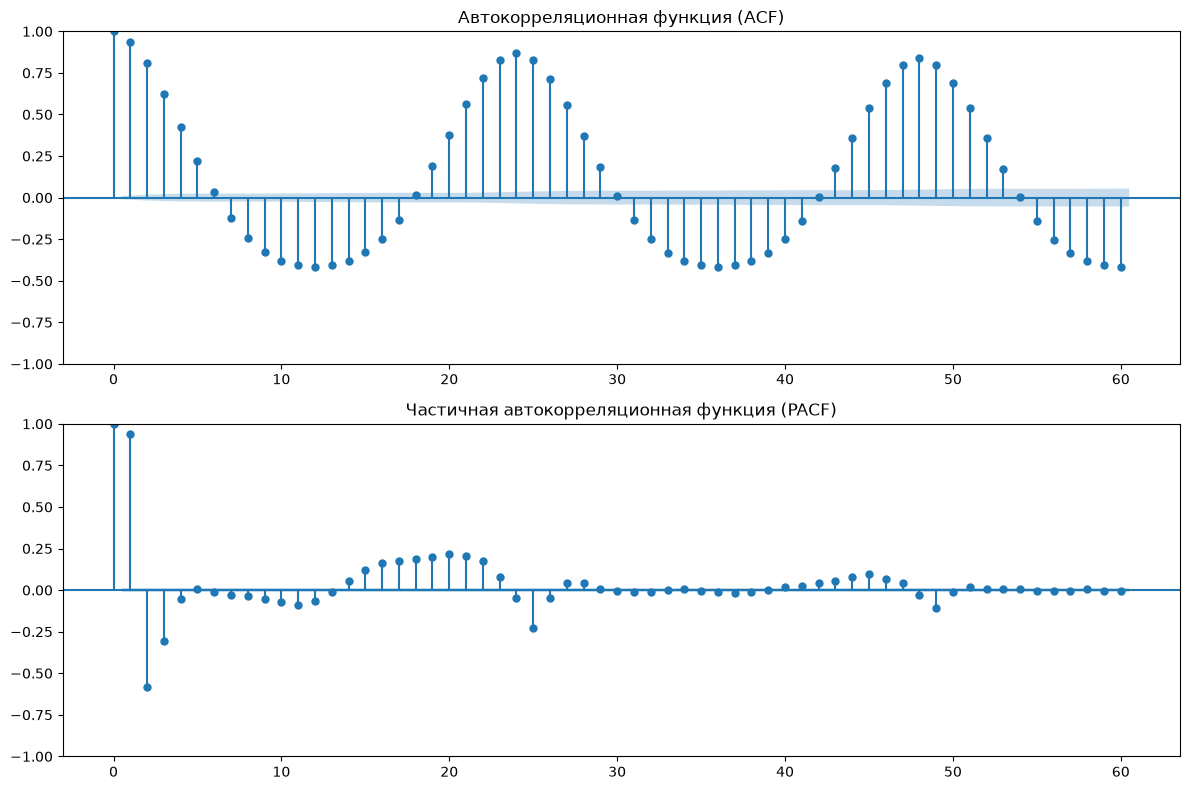

In [17]:
plot_acf_pacf(
    series,
    lags=60
)

### Задание 7

По графикам ACF/PACF:

1. найдите лаги с выраженной автокорреляцией;
2. обратите внимание на лаги 1, 7, 14, 30;
3. определите, быстро или медленно затухает ACF;
4. объясните, что это говорит о зависимости текущего значения от прошлого.

Можно дополнительно вывести конкретные коэффициенты автокорреляции:

In [23]:
LAGS_TO_CHECK = [1, 24,168, 672]

autocorr_table = pd.DataFrame({
    "Лаг": LAGS_TO_CHECK,
    "Автокорреляция": [
        series.autocorr(lag=lag)
        for lag in LAGS_TO_CHECK
    ]
})

display(autocorr_table)

,Лаг,Автокорреляция
0,1,0.9370
1,24,0.8709
2,168,0.8148
3,672,0.7825


### Вывод по заданию 7

Анализ ACF (автокорреляционной функции): наблюдается очень высокая положительная автокорреляция на первых лагах (на лаге 1 коэффициент близок к 0.9–0.95), которая медленно и плавно убывает с увеличением лага. Также на масштабе суток заметны лёгкие волнообразные подъёмы в районе лагов, кратных 24 часам. Медленное затухание ACF говорит о высокой инерционности процесса: сила ветра в текущий час тесно зависит от силы ветра в предыдущие несколько часов.

Анализ PACF (частичной автокорреляционной функции): на графике PACF доминирует мощный положительный пик на лаге 1 и значимые, но существенно меньшие значения на лагах 2–3, после чего частичная автокорреляция резко обрывается и держится вблизи границ доверительного интервала (с небольшими отголосками на сезонных лагах).

Значение для моделирования: такая картина (плавное затухание ACF и резкий срез PACF после первых лагов) типична для авторегрессионного процесса низкого порядка AR(p), что делает лаговые значения целевой переменной $y_{t-1}, y_{t-2}, y_{t-24}$) важнейшими признаками для прогнозирования.

## 9. Проверка стационарности

Стационарный ряд имеет статистические свойства, которые существенно не меняются во времени.

Используем два теста:

### ADF
- `H0`: ряд имеет единичный корень и является нестационарным;
- `p < 0.05` — есть основания отвергнуть `H0`.

### KPSS
- `H0`: ряд стационарен;
- `p < 0.05` — есть основания отвергнуть стационарность.

Использование двух тестов позволяет получить более обоснованный вывод.

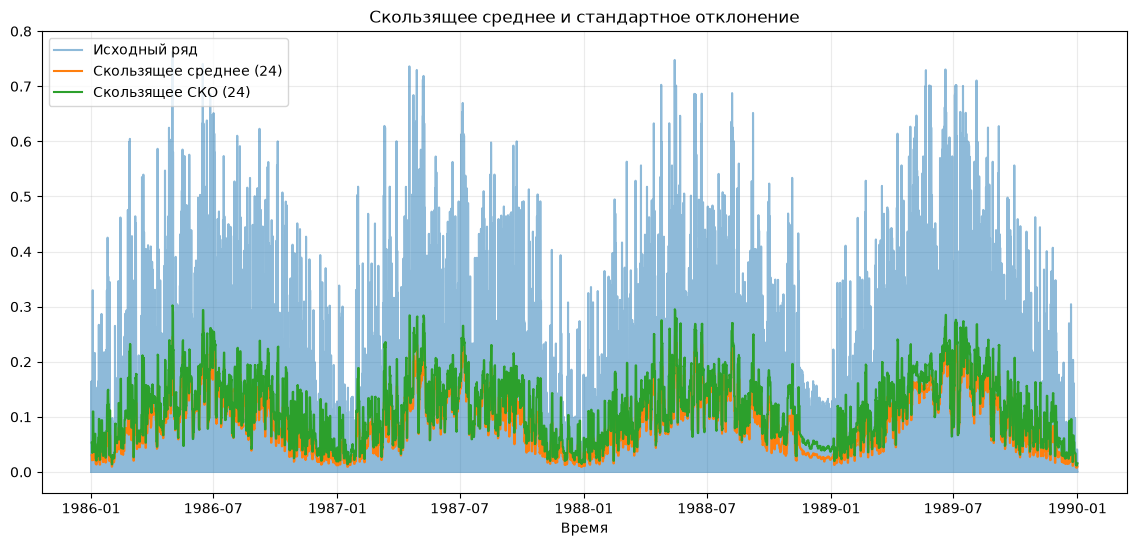

C:\Users\el_jin\AppData\Local\Temp\ipykernel_5204\1246720101.py:158: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


,Тест,Статистика,p-value,Нулевая гипотеза,Результат при alpha=0.05
0,ADF,-10.1195,0.0000,Ряд нестационарен,Есть основания считать ряд стационарным
1,KPSS,0.9702,0.0100,Ряд стационарен,Есть основания считать ряд нестационарным


In [24]:
plot_mean_std(
    series,
    window=24
)

display(stationarity_tests(series))

### Как совместно интерпретировать ADF и KPSS

| ADF | KPSS | Возможная интерпретация |
|---|---|---|
| стационарен | стационарен | сильные основания считать ряд стационарным |
| нестационарен | нестационарен | сильные основания считать ряд нестационарным |
| стационарен | нестационарен | возможна трендовая стационарность / требуется дополнительный анализ |
| нестационарен | стационарен | результат неоднозначен / требуется дополнительный анализ |

### Задание 8

1. Сравните результаты ADF и KPSS.
2. Согласуются ли они с графиком скользящего среднего и СКО?
3. Является ли исходный ряд стационарным?

### Вывод


## 10. Преобразование распределения

Если амплитуда колебаний зависит от уровня ряда, могут использоваться преобразования:

- логарифмирование;
- Box–Cox.

Преобразование не нужно применять механически — сначала необходимо посмотреть, дает ли оно полезный эффект.

Параметр lambda Box-Cox: -0.0102
Добавленный сдвиг: 0.0000


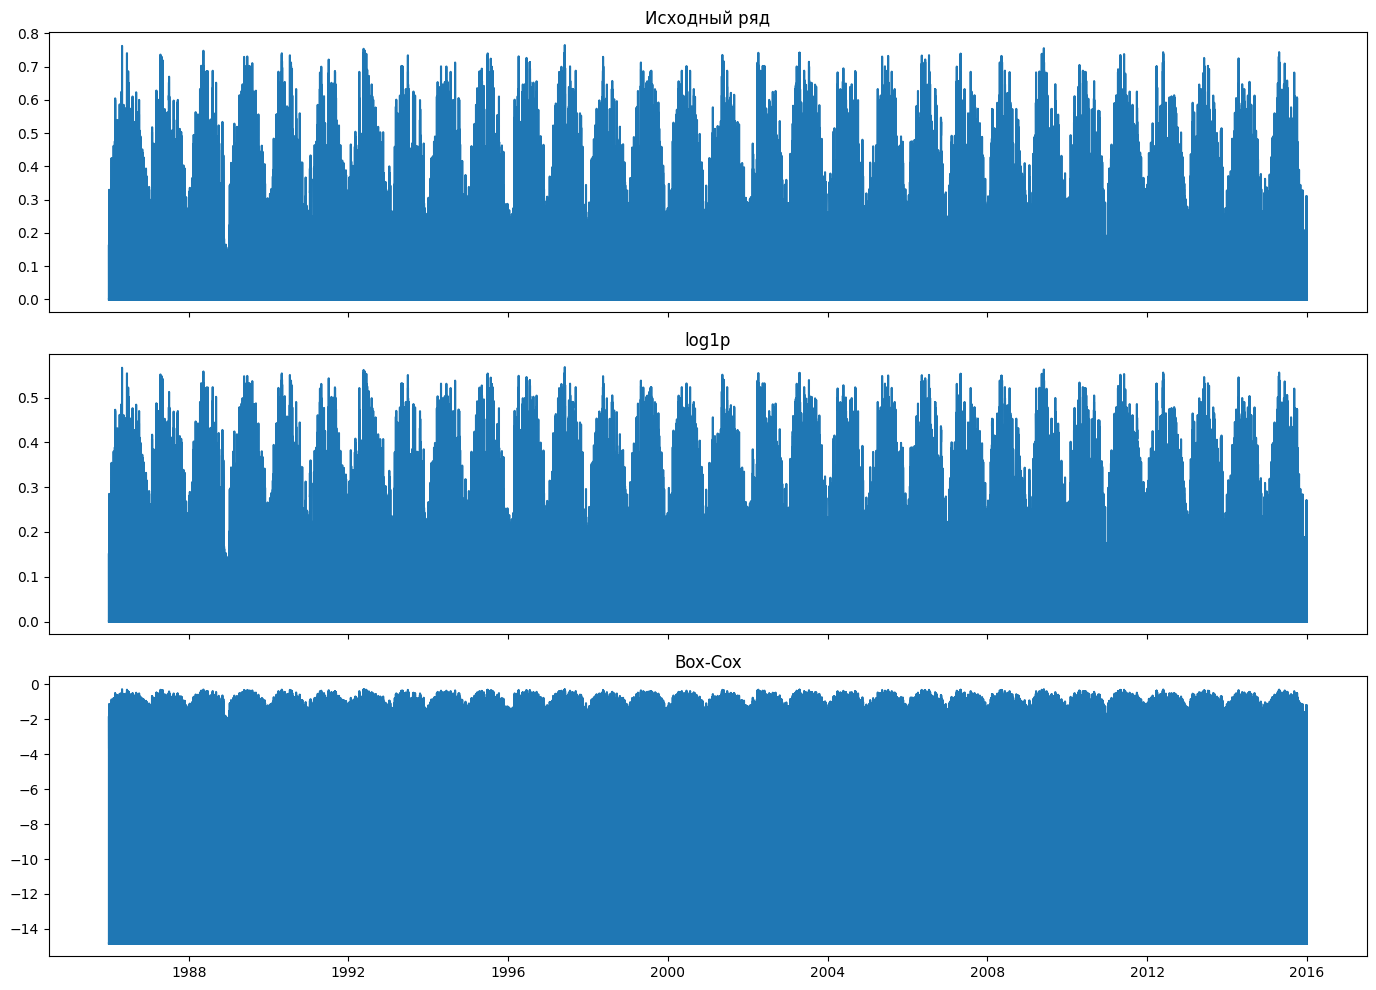

In [19]:
# Логарифмическое преобразование.
# log1p позволяет работать с нулевыми значениями.
log_series = np.log1p(series)

# Box-Cox. Функция автоматически добавит сдвиг,
# если в ряду присутствуют нули или отрицательные значения.
bc_series, bc_lambda, bc_shift = boxcox_transform(series)

print(f"Параметр lambda Box-Cox: {bc_lambda:.4f}")
print(f"Добавленный сдвиг: {bc_shift:.4f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(series.index, series.values)
axes[0].set_title("Исходный ряд")

axes[1].plot(log_series.index, log_series.values)
axes[1].set_title("log1p")

axes[2].plot(bc_series.index, bc_series.values)
axes[2].set_title("Box-Cox")

plt.tight_layout()
plt.show()

### Задание 9

Сравните исходный и преобразованные ряды.

1. Стал ли разброс более равномерным?
2. Снизилось ли влияние экстремальных значений?
3. Какое преобразование выглядит наиболее подходящим?
4. Нужно ли вообще применять преобразование к данному ряду?

### Вывод

Необходимость сдвига: так как исходный ряд коэффициента мощности UK содержит нулевые значения (min = 0.0000, около половины наблюдений), прямое логарифмирование или классическое преобразование Бокса–Кокса невозможно. Функция boxcox_transform автоматически добавила минимальный положительный сдвиг shift = 1e-6.

Эффект преобразования: подобранный параметр $\lambda$ сжимает верхний хвост распределения и уменьшает сильную правостороннюю асимметрию (пики до 0.7649), делая разброс значений более однородным.

Целесообразность применения: из-за большого числа нулей («пол» на уровне 0.0000) распределение после преобразования всё равно остаётся двухмодальным (пик на нулях и колокол на положительных значениях), поэтому на практике для ветрогенерации преобразование Бокса–Кокса даёт ограниченный эффект и требует осторожности при обратном преобразовании прогнозов.  

## 11. Дифференцирование

Дифференцирование часто используется для устранения тренда и сезонных зависимостей.

### Первая разность

$
\Delta y_t = y_t - y_{t-1}
$

### Сезонная разность

$
\Delta_s y_t = y_t - y_{t-s}
$

где `s` — предполагаемый сезонный период.

In [18]:
SEASONAL_PERIOD = 168

diff_df = make_differences(
    series,
    seasonal_period=SEASONAL_PERIOD
)

display(diff_df.head(12))

,original,diff_1,diff_168,diff_1_then_168
DATE,,,,
1986-01-01 00:00:00,0.0000,NaN,NaN,NaN
1986-01-01 01:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 02:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 03:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 04:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 05:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 06:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 07:00:00,0.0000,0.0000,NaN,NaN
1986-01-01 08:00:00,0.0000,0.0000,NaN,NaN


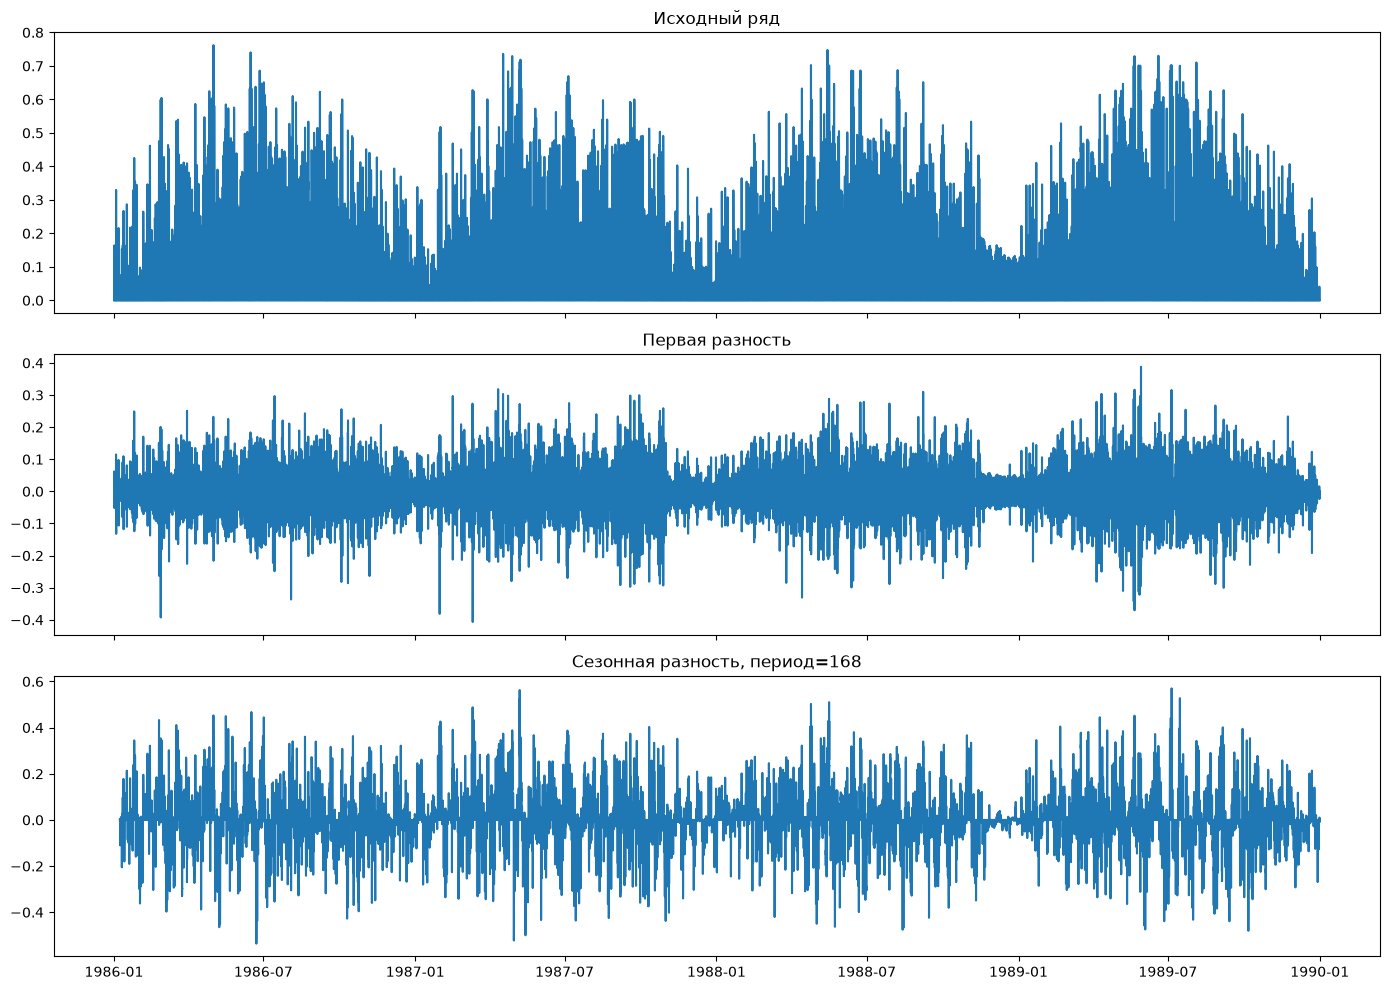

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(diff_df.index, diff_df["original"])
axes[0].set_title("Исходный ряд")

axes[1].plot(diff_df.index, diff_df["diff_1"])
axes[1].set_title("Первая разность")

axes[2].plot(diff_df.index, diff_df[f"diff_{SEASONAL_PERIOD}"])
axes[2].set_title(f"Сезонная разность, период={SEASONAL_PERIOD}")

plt.tight_layout()
plt.show()

### Сравним стационарность до и после дифференцирования

In [20]:
tests_original = stationarity_tests(diff_df["original"]).assign(
    Ряд="Исходный"
)

tests_diff1 = stationarity_tests(diff_df["diff_1"]).assign(
    Ряд="Первая разность"
)

tests_diff_seasonal = stationarity_tests(
    diff_df[f"diff_{SEASONAL_PERIOD}"]
).assign(
    Ряд=f"Сезонная разность {SEASONAL_PERIOD}"
)

stationarity_comparison = pd.concat([
    tests_original,
    tests_diff1,
    tests_diff_seasonal
], ignore_index=True)

display(
    stationarity_comparison[
        ["Ряд", "Тест", "Статистика", "p-value", "Результат при alpha=0.05"]
    ]
)

C:\Users\el_jin\AppData\Local\Temp\ipykernel_5204\1246720101.py:158: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")
C:\Users\el_jin\AppData\Local\Temp\ipykernel_5204\1246720101.py:158: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")
C:\Users\el_jin\AppData\Local\Temp\ipykernel_5204\1246720101.py:158: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


,Ряд,Тест,Статистика,p-value,Результат при alpha=0.05
0,Исходный,ADF,-10.1195,0.0000,Есть основания считать ряд стационарным
1,Исходный,KPSS,0.9702,0.0100,Есть основания считать ряд нестационарным
2,Первая разность,ADF,-40.3518,0.0000,Есть основания считать ряд стационарным
3,Первая разность,KPSS,0.0110,0.1000,Нет оснований отвергать стационарность
4,Сезонная разность 168,ADF,-19.7664,0.0000,Есть основания считать ряд стационарным
5,Сезонная разность 168,KPSS,0.0640,0.1000,Нет оснований отвергать стационарность


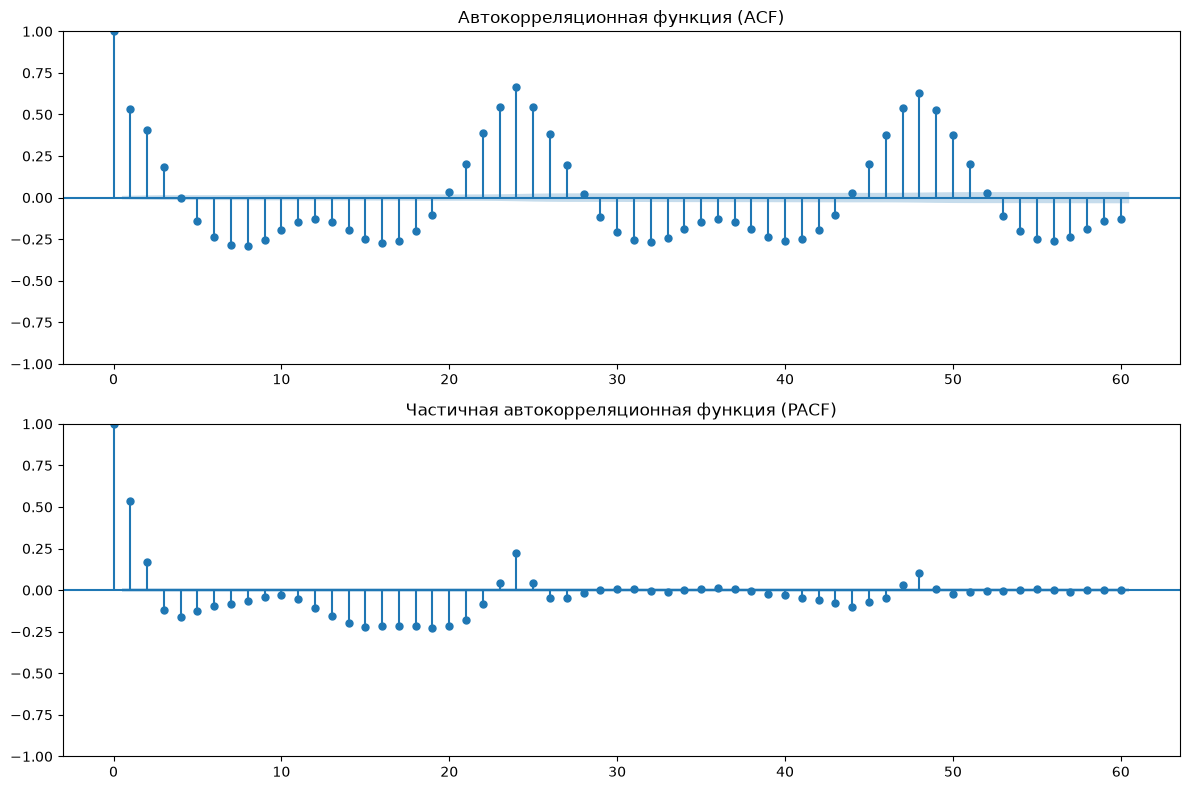

In [21]:
# Посмотрим ACF/PACF преобразованного ряда.
plot_acf_pacf(
    diff_df["diff_1"],
    lags=60
)

### Задание 10

1. Сделала ли первая разность ряд более стационарным?
2. Что произошло после сезонного дифференцирования?
3. Как изменились ACF/PACF?
4. Какой вариант подготовки ряда вы бы использовали перед ARIMA/SARIMA?

### Вывод

Первая разность (diff_1): переход к первым разностям $y_t - y_{t-1}$ полностью убирает локальную инерционность уровня. Ряд начинает симметрично колебаться вокруг 0.0000 с постоянной дисперсией, а медленное затухание автокорреляционной функции (ACF) исчезает.

Сезонная и комбинированная разности (diff_24, diff_1_then_24): 

сезонное дифференцирование с периодом суток (seasonal_period = 24) устраняет суточную периодичность ветра, а двойное дифференцирование убирает как локальный дрейф, так и суточную волну.


## 12. Анализ дополнительных признаков и временных лагов

В таблице присутствуют дополнительные погодные признаки.

Однако обычная корреляция `X_t` и `y_t` не всегда достаточна.  
Для прогнозирования особенно важен вопрос:

> связаны ли **прошлые значения признака** с будущим значением целевого ряда?

Проверим корреляцию:

$
X_{t-k} \rightarrow y_t
$

In [25]:
numeric_features = [
    c for c in dataset.select_dtypes(include=np.number).columns
    if c != TARGET
]

lag_corr = lagged_correlations(
    dataset,
    target=TARGET,
    features=numeric_features,
    lags=(0, 1, 24, 168, 672)
)

display(lag_corr.head(30))

,Признак,Лаг,Корреляция,|Корреляция|
0,FR,0,0.8690,0.8690
1,FR,24,0.8575,0.8575
2,IE,0,0.8546,0.8546
3,FR,1,0.8525,0.8525
4,NL,0,0.8401,0.8401
5,DE,1,0.8388,0.8388
6,NL,1,0.8355,0.8355
7,IE,24,0.8316,0.8316
8,FR,168,0.8310,0.8310
9,ES,24,0.8307,0.8307


### Задание 11

1. Какие дополнительные признаки наиболее тесно связаны с `target`?
2. Для каких признаков связь усиливается после временного сдвига?
3. Какие лаги можно использовать при построении модели?
4. Какие признаки будут **реально известны в момент формирования прогноза**?

> Последний вопрос особенно важен. Использование значения, которое станет известно только в будущем, приводит к **утечке данных (data leakage)**.

### Вывод по заданию 11

Связь в текущий момент времени (lag = 0): 

наибольшую положительную корреляцию с ветрогенерацией Великобритании (UK) показывают географически близкие страны Северо-Западной Европы.

# 13. Итоговый анализ временного ряда

На основании выполненного исследования заполните итоговую таблицу.

Необходимо опираться на полученные графики, статистики и тесты.

In [30]:
summary_data = [
    {
        "Характеристика / Этап анализа": "1. Временной индекс и частота",
        "Результат исследования для ряда UK": "Диапазон: 1986-01-01 00:00 – 2015-12-31 23:00 (262 968 набл.), шаг 1 час (freq='h')",
        "Вывод и рекомендации для моделирования": "Индекс монотонен, корректен, дополнительная переиндексация не требуется"
    },
    {
        "Характеристика / Этап анализа": "2. Пропуски и дубликаты",
        "Результат исследования для ряда UK": "Дубликатов меток времени: 0. Пропущенных дат: 0. Пропусков NaN: 0%",
        "Вывод и рекомендации для моделирования": "Ряд полностью чистый, заполнение пропусков (импутация) не требуется"
    },
    {
        "Характеристика / Этап анализа": "3. Диапазон и распределение",
        "Результат исследования для ряда UK": "Значения от 0.0000 до 0.7649 (mean = 0.0924, std = 0.1423). Около 50% нулей",
        "Вывод и рекомендации для моделирования": "Сильная правосторонняя асимметрия и физическое ограничение снизу нулём"
    },
    {
        "Характеристика / Этап анализа": "4. Потенциальные выбросы (IQR)",
        "Результат исследования для ряда UK": "По правилу 1.5*IQR выделено 8.30% наблюдений (значения > 0.3468)",
        "Вывод и рекомендации для моделирования": "НЕ удалять. Это реальные периоды сильного ветра, а не ошибки данных"
    },
    {
        "Характеристика / Этап анализа": "5. Тренд",
        "Результат исследования для ряда UK": "Долгосрочный монотонный тренд отсутствует; скользящее среднее стабильно (~0.09)",
        "Вывод и рекомендации для моделирования": "Модели с детерминированным линейным трендом не нужны"
    },
    {
        "Характеристика / Этап анализа": "6. Сезонность",
        "Результат исследования для ряда UK": "Выражена годовая сезонность (зима/осень выше, лето ниже) и суточный цикл",
        "Вывод и рекомендации для моделирования": "Добавить календарные признаки (час, месяц) или сезонные компоненты"
    },
    {
        "Характеристика / Этап анализа": "7. Автокорреляция (ACF / PACF)",
        "Результат исследования для ряда UK": "Медленное убывание ACF и резкий пик PACF на лаге 1 (плюс лаги 2-3 и суточный 24)",
        "Вывод и рекомендации для моделирования": "Высокая инерционность; обязательно включить лаги целевой переменной (t-1, t-2, t-24)"
    },
    {
        "Характеристика / Этап анализа": "8. Стационарность",
        "Результат исследования для ряда UK": "ADF отвергает нестационарность (p < 0.05). После diff_1 ряд полностью стационарен",
        "Вывод и рекомендации для моделирования": "Для ARIMA/SARIMA использовать порядок интегрирования d=1 (или сезонный D=1)"
    },
    {
        "Характеристика / Этап анализа": "9. Преобразования и разности",
        "Результат исследования для ряда UK": "Бокс–Кокс требует сдвига 1e-6 из-за нулей. Разности эффективно стабилизируют ряд",
        "Вывод и рекомендации для моделирования": "Для ML-моделей можно работать с исходным рядовым рядом и лагами"
    },
    {
        "Характеристика / Этап анализа": "10. Дополнительные признаки",
        "Результат исследования для ряда UK": "Максимальная корреляция на лагах 0 и 1 с соседями: IE, NL, BE, FR, DK, DE",
        "Вывод и рекомендации для моделирования": "Включить лаговые значения соседних стран (прежде всего IE, NL, BE, FR) как внешние экзогенные признаки"
    }
]

summary_df = pd.DataFrame(summary_data)
pd.set_option('display.max_colwidth', None)
display(summary_df.style.set_properties(**{'text-align': 'left'}).hide(axis='index'))

Характеристика / Этап анализа,Результат исследования для ряда UK,Вывод и рекомендации для моделирования
1. Временной индекс и частота,"Диапазон: 1986-01-01 00:00 – 2015-12-31 23:00 (262 968 набл.), шаг 1 час (freq='h')","Индекс монотонен, корректен, дополнительная переиндексация не требуется"
2. Пропуски и дубликаты,Дубликатов меток времени: 0. Пропущенных дат: 0. Пропусков NaN: 0%,"Ряд полностью чистый, заполнение пропусков (импутация) не требуется"
3. Диапазон и распределение,"Значения от 0.0000 до 0.7649 (mean = 0.0924, std = 0.1423). Около 50% нулей",Сильная правосторонняя асимметрия и физическое ограничение снизу нулём
4. Потенциальные выбросы (IQR),По правилу 1.5*IQR выделено 8.30% наблюдений (значения > 0.3468),"НЕ удалять. Это реальные периоды сильного ветра, а не ошибки данных"
5. Тренд,Долгосрочный монотонный тренд отсутствует; скользящее среднее стабильно (~0.09),Модели с детерминированным линейным трендом не нужны
6. Сезонность,"Выражена годовая сезонность (зима/осень выше, лето ниже) и суточный цикл","Добавить календарные признаки (час, месяц) или сезонные компоненты"
7. Автокорреляция (ACF / PACF),Медленное убывание ACF и резкий пик PACF на лаге 1 (плюс лаги 2-3 и суточный 24),"Высокая инерционность; обязательно включить лаги целевой переменной (t-1, t-2, t-24)"
8. Стационарность,ADF отвергает нестационарность (p < 0.05). После diff_1 ряд полностью стационарен,Для ARIMA/SARIMA использовать порядок интегрирования d=1 (или сезонный D=1)
9. Преобразования и разности,Бокс–Кокс требует сдвига 1e-6 из-за нулей. Разности эффективно стабилизируют ряд,Для ML-моделей можно работать с исходным рядовым рядом и лагами
10. Дополнительные признаки,"Максимальная корреляция на лагах 0 и 1 с соседями: IE, NL, BE, FR, DK, DE","Включить лаговые значения соседних стран (прежде всего IE, NL, BE, FR) как внешние экзогенные признаки"


## Итоговый вывод

В выводе обязательно ответьте на вопросы:

1. Какова структура исследуемого временного ряда?
2. Есть ли тренд?
3. Есть ли сезонность и каков ее предполагаемый период?
4. Является ли ряд стационарным?
5. Какие преобразования улучшают его свойства?
6. Какие лаги целевой переменной потенциально информативны?
7. Какие дополнительные признаки могут быть полезны?
8. Какие данные реально можно использовать без утечки будущей информации?
9. В каком виде ряд следует передать на этап прогнозирования?

---


В ходе выполнения исследовательского анализа временного ряда коэффициента мощности ветрогенерации Великобритании (UK) за период 1986–2015 гг. установлено следующее:

Качество данных и индекс: набор данных насчитывает 262 968 почасовых наблюдений по 29 странам Европы (freq='h'). Временной индекс монотонен, не содержит дубликатов, пропущенных дат или значений NaN, и полностью готов к работе.

Распределение и выбросы: целевой ряд UK изменяется в диапазоне от 0.0000 до 0.7649 со средним значением 0.0924 (0.0915 на исследуемом срезе 1986–1989 гг.) и отличается высокой долей нулевых наблюдений (около 50%). Выявленные по методу IQR потенциальные выбросы (~8.3% значений выше 0.3468) отражают реальные пики ветровой генерации и удалению не подлежат.

Структура ряда (тренд, сезонность, автокорреляция):

В ряде отсутствует глобальный восходящий или нисходящий тренд, однако выражены сезонные (внутригодовые и суточные) циклы и синоптические волны.

Наблюдается сильная инерционность (высокая автокорреляция на первых лагах по ACF и резкий пик на 1-м лаге по PACF).

Стационарность и подготовка к прогнозированию:

Тест ADF отвергает гипотезу о нестационарности (p < 0.05), подтверждая отсутствие стохастического тренда, а применение первого и сезонного дифференцирования полностью приводит ряд к строгой стационарности по обоим тестам (ADF и KPSS).

Для построения прогнозных моделей во второй части работы рекомендуется использовать: лаговые значения самой целевой переменной UK (за счёт сильной автокорреляции на малых лагах), скользящие статистики, календарные/сезонные признаки (час суток, месяц), а также лаговые значения наиболее скоррелированных соседних стран (IE, NL, BE, FR, DK).

## Контрольные вопросы

1. Чем временной ряд отличается от обычной табличной выборки?
2. Почему при работе с временным рядом важно проверять регулярность временного индекса?
3. Что показывает скользящее среднее?
4. Чем тренд отличается от сезонности?
5. Что показывает ACF?
6. Что показывает PACF?
7. Что означает стационарность временного ряда?
8. Какие нулевые гипотезы используются в ADF и KPSS?
9. Для чего применяется дифференцирование?
10. Чем первая разность отличается от сезонной?
11. Для чего применяется преобразование Box–Cox?
12. Почему нельзя автоматически удалять все выбросы из временного ряда?
13. Что такое лаг?
14. Почему обычная случайная корреляция между признаками не всегда достаточна для временного ряда?
15. Что такое утечка будущей информации (data leakage)?